In [1]:
# 匯入TensorFlow中的Keras套件，用來建立及訓練神經網路模型
from tensorflow import keras

# 匯入Sequential模型，可以依序堆疊神經網路的各個層
from keras.models import Sequential

# 匯入Dense（全連接層）、Conv2D（卷積層）、MaxPooling2D（最大池化層）、Flatten（資料攤平層）
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

# 建立Sequential模型，讓神經網路的各層依照加入順序進行運算
model=Sequential()

# 加入卷積層，用來從圖片中擷取特徵
# (1.)filters=16：設定16個卷積濾波器(也就是16個不同的特徵偵測器)
# (2.)kernel_size=(5, 5)：每個濾波器的大小為5×5
# (3.)input_shape=(28, 28, 1)：輸入圖片28列、28行、通道數為1（灰階圖片）
# (4.)activation='relu'：使用ReLU啟動函數，將負數轉換為0，正數則保留
model.add(Conv2D(filters=16, kernel_size=(5, 5), input_shape=(28, 28, 1), activation='relu'))

# 加入最大池化層（MaxPooling2D），縮小特徵圖的尺寸
# pool_size=(2, 2)：使用2×2的區域進行池化，每個區域取出最大的數值，可以減少後續運算量，並保留較重要的特徵
model.add(MaxPooling2D(pool_size=(2, 2)))

#再增加一個卷積層及一個最大池化層
'''model.add(Conv2D(filters=36, kernel_size=(5, 5), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))'''

# 加入Flatten層，將前面卷積及池化後的多維特徵圖攤平成一維資料，讓後面的Dense層可以接收這些特徵
model.add(Flatten())

# 加入輸出層，模型會根據機率最高的神經元，判斷圖片最可能是哪個數字
# (1.)Dense(10)：設定10個神經元，分別對應數字0～9
# (2.)softmax：會將輸出轉換成總和為1的機率分布
model.add(Dense(10, activation='softmax'))

# 顯示模型架構摘要，包括每一層的輸出形狀及參數數量
model.summary()

# 設定模型的訓練方式
# (1.)optimizer='rmsprop'：使用RMSprop優化器調整神經網路的權重
# (2.)loss='categorical_crossentropy'：用於多分類問題，且標籤已轉換成One-hot編碼(由0和1組成的陣列)
# (3.)metrics=['accuracy']：訓練及評估時顯示準確率
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,466 (91.66 KB)

 Trainable params: 23,466 (91.66 KB)

 Non-trainable params: 0 (0.00 B)

In [2]:
# 指定使用Keras內建的MNIST手寫數字資料
mnist=keras.datasets.mnist

# 載入MNIST資料集，並分成訓練資料及測試資料
# (1.)train_data：60000張訓練圖片
# (2.)train_label：60000個訓練圖片對應的正確數字
# (3.)test_data：10000張測試圖片
# (4.)test_label：10000個測試圖片對應的正確數字
(train_data, train_label), (test_data, test_label) = mnist.load_data()

# 複製原始測試標籤，保留原本0～9的整數格式
# 後續製作混淆矩陣時，需要使用原始整數標籤
test_label_original=test_label #for crosstab

# 將訓練標籤轉換成One-hot編碼(例如原本數字3會轉換成[0,0,0,1,0,0,0,0,0,0])
# 每個數字使用10個位置表示，正確數字的位置為1，其餘位置為0
train_label = keras.utils.to_categorical(train_label)

# 將測試標籤也轉換成One-hot編碼，讓測試標籤的格式符合模型使用的categorical_crossentropy損失函數
test_label = keras.utils.to_categorical(test_label)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
# 開始訓練模型，並將訓練過程的紀錄儲存在train_history變數中
# (1.)train_data：提供訓練圖片
# (2.)train_label：提供圖片對應的One-hot正確答案
# (3.)epochs=50：將全部訓練資料完整訓練50次
# (4.)batch_size=512：每次取512筆資料進行一次權重更新
train_history=model.fit(train_data,train_label,epochs=50,batch_size=512)

Epoch 1/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.8226 - loss: 4.2079 
Epoch 2/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9559 - loss: 0.2994
Epoch 3/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9721 - loss: 0.1356
Epoch 4/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9800 - loss: 0.0838
Epoch 5/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9848 - loss: 0.0561
Epoch 6/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9885 - loss: 0.0429
Epoch 7/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9906 - loss: 0.0320
Epoch 8/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9923 - loss: 0.0250
Epoch 9/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9934 - loss: 0.0216
Epoch 10/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9945 - loss: 0.0183
Epoch 11/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9957 - loss: 0.0138
Epoch 12/50
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/st

In [4]:
# 使用測試資料評估模型的辨識能力，evaluate會回傳損失值（loss）及準確率（accuracy）
score=model.evaluate(test_data, test_label)

# 印出測試資料的準確率。score[0]代表損失值，score[1]代表準確率
print(score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9827 - loss: 0.2231
0.982699990272522


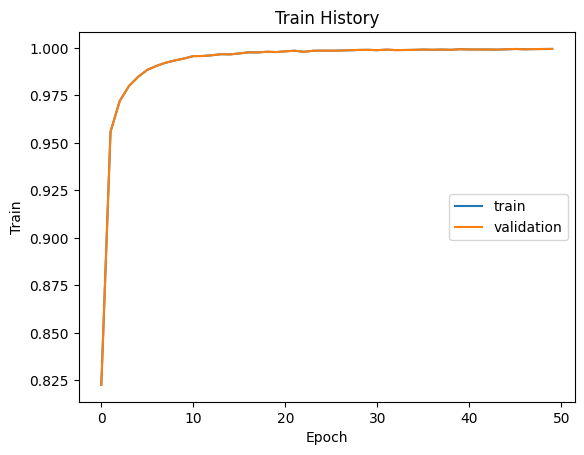

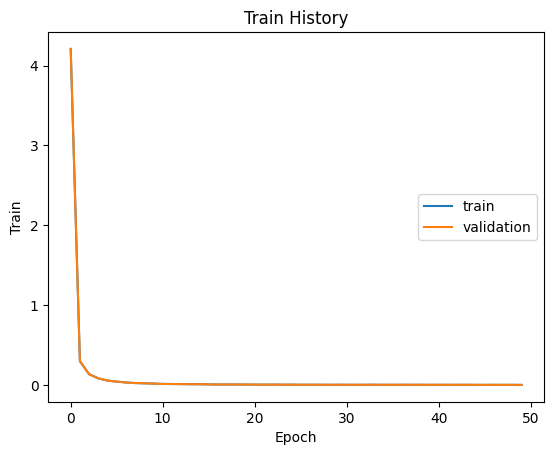

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(10000, 10)


predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,969,0,1,1,2,0,4,0,3,0
1,0,1124,3,0,2,2,1,1,2,0
2,3,1,1009,0,3,0,1,9,6,0
3,0,0,1,1000,0,4,0,2,2,1
4,2,0,0,0,969,0,1,2,1,7
5,1,0,0,9,0,876,2,0,3,1
6,6,1,0,1,3,3,942,0,2,0
7,0,2,9,1,2,0,0,1000,2,12
8,4,0,1,3,0,0,3,4,957,2


In [5]:
# 繪製訓練過程中的準確率及損失值歷史圖，並匯入Matplotlib的pyplot模組，用來繪製圖表
import matplotlib.pyplot as plt

# 匯入NumPy套件，用來進行陣列及數值運算
import numpy as np

# 定義一個函數，用來繪製模型訓練過程的歷史紀錄
# (1.)train_history：model.fit()回傳的訓練歷史資料
# (2.)train：指定要繪製的訓練指標，例如accuracy或loss
# (3.)validation：指定要繪製的另一組指標，例如驗證資料的accuracy(準確率)或loss(損失值)
def show_train_history(train_history, train, validation):

    # 繪製訓練資料在每個Epoch的指標變化
    plt.plot(train_history.history[train])

    # 繪製驗證資料在每個Epoch的指標變化
    plt.plot(train_history.history[validation])

    # 設定圖表標題
    plt.title('Train History')

    # 設定縱軸名稱
    plt.ylabel('Train')

    # 設定橫軸名稱，代表訓練次數（Epoch）
    plt.xlabel('Epoch')

    # 設定圖例，分別代表訓練資料及驗證資料
    # loc='center right'：將圖例放在圖表右側中央
    plt.legend(['train', 'validation'], loc='center right')

    # 顯示圖表
    plt.show()


# 呼叫函數，繪製訓練準確率的變化圖
show_train_history(train_history, 'accuracy', 'accuracy')

# 呼叫函數，繪製訓練損失值的變化圖
show_train_history(train_history, 'loss', 'loss')


# 建立混淆矩陣（Confusion Matrix），用來比較實際答案與模型預測結果

# 匯入Pandas套件，用來整理及分析資料表格
import pandas as pd

# 使用訓練完成的模型，對測試圖片進行預測，預測結果會包含每張圖片屬於數字0～9的機率
prediction = model.predict(test_data)

# 使用argmax找出每張圖片預測機率最高的位置，axis=1代表逐筆資料尋找最大值的位置
prediction_label=np.argmax(prediction,axis=1)

# 印出原始測試標籤的形狀。預期結果為(10000,)，代表有10000個測試標籤
print(test_label.shape)

# 建立交叉表，呈現實際數字與模型預測數字的對照結果
# (1.)test_label_original：實際正確答案
# (2.)prediction_label：模型預測的數字
# (3.)rownames=['label']：將列名稱設定為實際標籤
# (4.)colnames=['predict']：將欄名稱設定為模型預測結果
pd.crosstab(test_label_original, prediction_label, rownames=['label'], colnames=['predict'])